# MNIST: CNN Accuracy vs Computational Cost (PyTorch)

This notebook compares a dense neural network and three CNN architectures on MNIST. Students will measure accuracy, parameter counts, model size, and training time to understand the tradeoff between model complexity and performance.

In [1]:
# requirements
%pip install torch torchvision pandas matplotlib

  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/124.1 MB 5.2 MB/s eta 0:00:24
    --------------------------------------- 1.6/124.1 MB 4.6 MB/s eta 0:00:27
    --------------------------------------- 2.4/124.1 MB 4.3 MB/s eta 0:00:29
   - -------------------------------------- 3.1/124.1 MB 4.5 MB/s eta 0:00:28
   - -------------------------------------- 4.2/124.1 MB 4.4 MB/s eta 0:00:28
   - -------------------------------------- 5.2/124.1 MB 4.5 MB/s eta 0:00:27
   -- ------------------------------------- 6.3/124.1 MB 4.6 MB/s eta 0:00:26
   -- ------------------------------------- 7.1/124.1 MB 4.6 MB/s eta 0:00:26
   -- ------------------------------------- 7.9/1

In [ ]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cpu


In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset,batch_size=128,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=128,shuffle=False)

#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
device = torch.device("cpu")
print("Device:", device)

100.0%
100.0%
100.0%
100.0%


Device: cpu


In [4]:
class DenseNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.ReLU(),
            nn.Linear(128,10)
        )

    def forward(self,x):
        return self.layers(x)

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1,8,3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(8*13*13,10)
        )

    def forward(self,x):
        return self.network(x)

In [6]:
class MediumCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,16,3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16,32,3),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*5*5,64),
            nn.ReLU(),
            nn.Linear(64,10)
        )

    def forward(self,x):
        return self.classifier(self.features(x))

In [7]:
class LargeCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(32,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(64,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7,128),
            nn.ReLU(),
            nn.Linear(128,10)
        )

    def forward(self,x):
        return self.classifier(self.features(x))

In [8]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model, epochs=3):

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    start = time.time()

    for epoch in range(epochs):
        model.train()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

    train_time = time.time() - start

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total

    return accuracy, train_time

In [9]:
models = {
    "Dense": DenseNet(),
    "Small CNN": SmallCNN(),
    "Medium CNN": MediumCNN(),
    "Large CNN": LargeCNN()
}

results = []

for name, model in models.items():

    print(f"Training {name}")

    accuracy, train_time = train_and_evaluate(model, epochs=3)

    params = count_params(model)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Parameters": params,
        "Model Size (MB)": params * 4 / (1024**2),
        "Train Time (s)": train_time
    })

df = pd.DataFrame(results)
df.sort_values("Accuracy", ascending=False)

Training Dense
Training Small CNN
Training Medium CNN
Training Large CNN


,Model,Accuracy,Parameters,Model Size (MB),Train Time (s)
3,Large CNN,0.9889,467818,1.784584,251.762427
2,Medium CNN,0.9835,56714,0.216347,60.848131
1,Small CNN,0.9655,13610,0.051918,103.317521
0,Dense,0.9629,101770,0.388222,76.445527


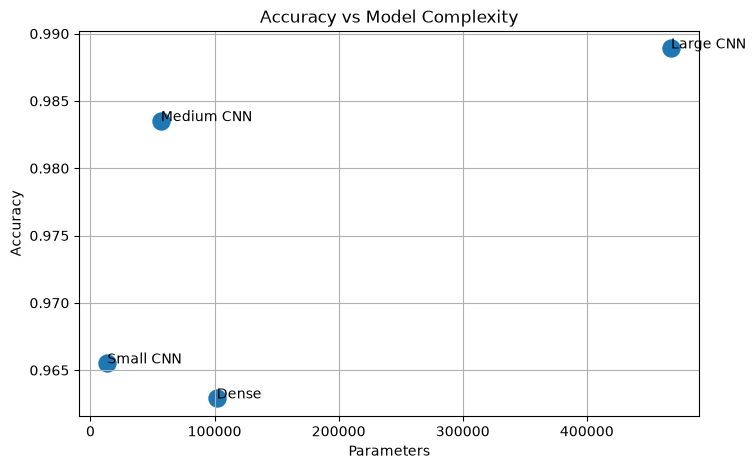

In [10]:
plt.figure(figsize=(8,5))
plt.scatter(df["Parameters"], df["Accuracy"], s=150)

for _, row in df.iterrows():
    plt.annotate(row["Model"], (row["Parameters"], row["Accuracy"]))

plt.xlabel("Parameters")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Model Complexity")
plt.grid(True)
plt.show()

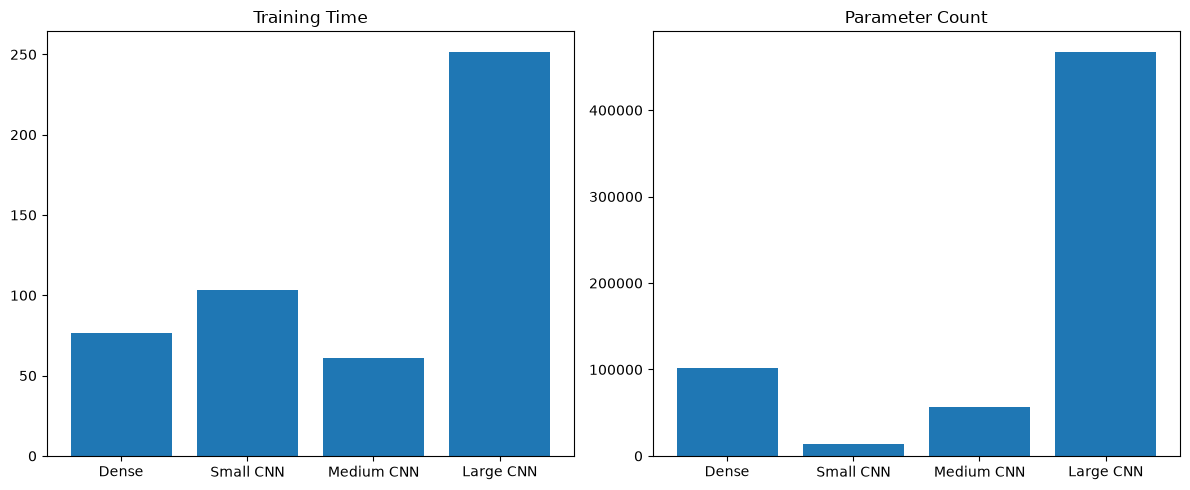

In [11]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].bar(df["Model"], df["Train Time (s)"])
ax[0].set_title("Training Time")

ax[1].bar(df["Model"], df["Parameters"])
ax[1].set_title("Parameter Count")

plt.tight_layout()
plt.show()

## Optional FLOP and Memory Analysis
Install torchinfo and inspect a model.

In [12]:
%pip install torchinfo
from torchinfo import summary
summary(LargeCNN(), input_size=(1,1,28,28))

Note: you may need to restart the kernel to use updated packages.


Layer (type:depth-idx)                   Output Shape              Param #
LargeCNN                                 [1, 10]                   --
├─Sequential: 1-1                        [1, 64, 7, 7]             --
│    └─Conv2d: 2-1                       [1, 32, 28, 28]           320
│    └─ReLU: 2-2                         [1, 32, 28, 28]           --
│    └─Conv2d: 2-3                       [1, 32, 28, 28]           9,248
│    └─ReLU: 2-4                         [1, 32, 28, 28]           --
│    └─MaxPool2d: 2-5                    [1, 32, 14, 14]           --
│    └─Conv2d: 2-6                       [1, 64, 14, 14]           18,496
│    └─ReLU: 2-7                         [1, 64, 14, 14]           --
│    └─Conv2d: 2-8                       [1, 64, 14, 14]           36,928
│    └─ReLU: 2-9                         [1, 64, 14, 14]           --
│    └─MaxPool2d: 2-10                   [1, 64, 7, 7]             --
├─Sequential: 1-2                        [1, 10]                   --
│  

## Discussion Questions
1. Why do CNNs outperform dense networks on images?
2. Which model has the best accuracy-per-parameter ratio?
3. At what point do larger models provide diminishing returns?
4. Which model would be most appropriate for mobile deployment?
5. How do parameter count and training time relate to accuracy?

## Part 2: Compact CNN design

The baseline comparison above establishes the reference point. This self-contained experiment trains a new MNIST CNN, records validation performance, evaluates on the held-out test set, and compares measured results with the baseline.

Epoch 01/8 | loss=0.2024 | validation accuracy=98.32%
Epoch 02/8 | loss=0.0618 | validation accuracy=98.30%
Epoch 03/8 | loss=0.0468 | validation accuracy=98.40%
Epoch 04/8 | loss=0.0393 | validation accuracy=98.86%
Epoch 05/8 | loss=0.0319 | validation accuracy=98.72%
Epoch 06/8 | loss=0.0281 | validation accuracy=98.74%
Epoch 07/8 | loss=0.0244 | validation accuracy=98.90%
Epoch 08/8 | loss=0.0226 | validation accuracy=99.18%

Proposed CNN test accuracy: 99.14%
Trainable parameters: 94,394 | Training time: 367.8 seconds (CPU)
Constraint check: PASS


Model,Accuracy (%),Parameters,Model Size (MB),Train Time (s),Meets both constraints
Compact CNN (proposed),99.14,94394,0.360085,367.814781,True
Large CNN,98.89,467818,1.784584,251.762427,False
Medium CNN,98.35,56714,0.216347,60.848131,False
Small CNN,96.55,13610,0.051918,103.317521,False
Dense,96.29,101770,0.388222,76.445527,False


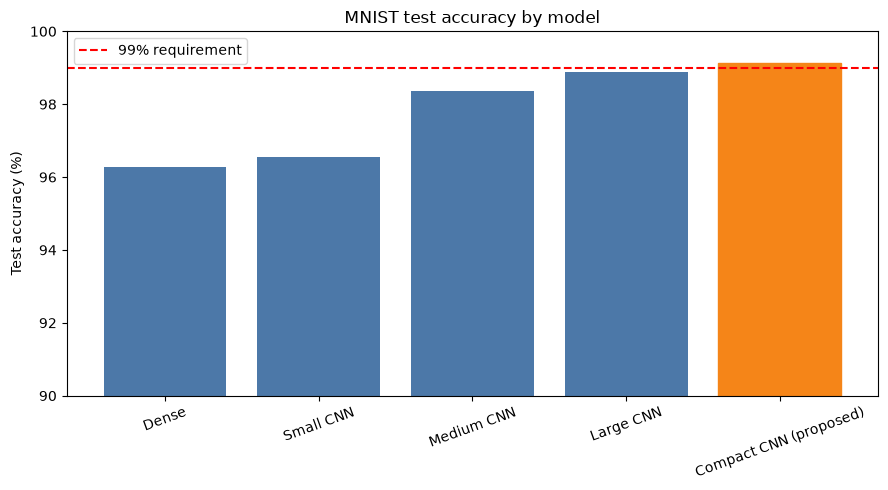

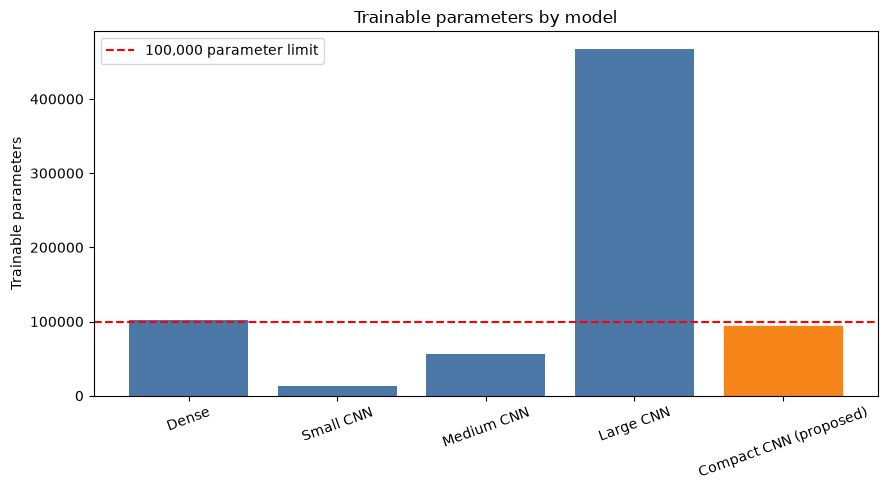

In [11]:
import random
import time
from torch.utils.data import random_split

SEED = 470
EPOCHS = 8
BATCH_SIZE = 128
random.seed(SEED)
torch.manual_seed(SEED)

transform_new = transforms.ToTensor()
all_train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform_new)
test_data_new = datasets.MNIST(root="./data", train=False, download=True, transform=transform_new)
train_data_new, validation_data_new = random_split(
    all_train_data, [55_000, 5_000], generator=torch.Generator().manual_seed(SEED)
)
train_loader_new = DataLoader(train_data_new, batch_size=BATCH_SIZE, shuffle=True)
validation_loader_new = DataLoader(validation_data_new, batch_size=BATCH_SIZE, shuffle=False)
test_loader_new = DataLoader(test_data_new, batch_size=BATCH_SIZE, shuffle=False)

class CompactCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 48, 3, padding=1, bias=False), nn.BatchNorm2d(48), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(48 * 7 * 7, 32), nn.ReLU(inplace=True),
            nn.Dropout(0.10), nn.Linear(32, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


device = torch.device("cpu")  # Matches the baseline execution device.
model = CompactCNN().to(device)
parameter_count = count_params(model)
assert parameter_count <= 100_000, f"Parameter limit exceeded: {parameter_count:,}"
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
validation_history = []
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    examples_seen = 0
    for images, labels in train_loader_new:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        examples_seen += labels.size(0)

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in validation_loader_new:
            predictions = model(images.to(device)).argmax(dim=1)
            correct += (predictions == labels.to(device)).sum().item()
    validation_accuracy = correct / len(validation_data_new)
    validation_history.append(validation_accuracy)
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss={running_loss / examples_seen:.4f} | validation accuracy={validation_accuracy:.2%}")

training_time = time.time() - start_time
model.eval()
test_correct = 0
with torch.no_grad():
    for images, labels in test_loader_new:
        predictions = model(images.to(device)).argmax(dim=1)
        test_correct += (predictions == labels.to(device)).sum().item()
test_accuracy = test_correct / len(test_data_new)

baseline_results = [
    {"Model": "Dense", "Accuracy": 0.9629, "Parameters": 101770, "Train Time (s)": 76.445527},
    {"Model": "Small CNN", "Accuracy": 0.9655, "Parameters": 13610, "Train Time (s)": 103.317521},
    {"Model": "Medium CNN", "Accuracy": 0.9835, "Parameters": 56714, "Train Time (s)": 60.848131},
    {"Model": "Large CNN", "Accuracy": 0.9889, "Parameters": 467818, "Train Time (s)": 251.762427},
]
comparison_results = pd.DataFrame(baseline_results + [{
    "Model": "Compact CNN (proposed)", "Accuracy": test_accuracy,
    "Parameters": parameter_count, "Train Time (s)": training_time,
}])
comparison_results["Accuracy (%)"] = comparison_results["Accuracy"] * 100
comparison_results["Model Size (MB)"] = comparison_results["Parameters"] * 4 / (1024 ** 2)
comparison_results["Meets both constraints"] = (
    (comparison_results["Accuracy"] >= 0.99) & (comparison_results["Parameters"] <= 100_000)
)
print(f"\nProposed CNN test accuracy: {test_accuracy:.2%}")
print(f"Trainable parameters: {parameter_count:,} | Training time: {training_time:.1f} seconds (CPU)")
display(comparison_results[["Model", "Accuracy (%)", "Parameters", "Model Size (MB)", "Train Time (s)", "Meets both constraints"]].sort_values("Accuracy (%)", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(comparison_results["Model"], comparison_results["Accuracy (%)"], color="#4C78A8")
for bar, name in zip(bars, comparison_results["Model"]):
    if name == "Compact CNN (proposed)":
        bar.set_color("#F58518")
ax.axhline(99, color="red", linestyle="--", linewidth=1.5, label="99% requirement")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("MNIST test accuracy by model")
ax.set_ylim(90, 100)
ax.tick_params(axis="x", rotation=20)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(comparison_results["Model"], comparison_results["Parameters"], color="#4C78A8")
for bar, name in zip(bars, comparison_results["Model"]):
    if name == "Compact CNN (proposed)":
        bar.set_color("#F58518")
ax.axhline(100_000, color="red", linestyle="--", linewidth=1.5, label="100,000 parameter limit")
ax.set_ylabel("Trainable parameters")
ax.set_title("Trainable parameters by model")
ax.ticklabel_format(axis="y", style="plain")
ax.tick_params(axis="x", rotation=20)
ax.legend()
fig.tight_layout()
plt.show()
print("Constraint check:", "PASS" if test_accuracy >= 0.99 and parameter_count <= 100_000 else "NOT YET MET")

## Engineering justification

### Problem and baseline

This task is ten-class handwritten-digit recognition on MNIST. The saved baseline compares a dense model and three CNNs after three epochs. Its results show a clear accuracy/size trade-off: Dense reaches 96.29% with 101,770 trainable parameters; Small CNN reaches 96.55% with 13,610; Medium CNN reaches 98.35% with 56,714; and Large CNN reaches 98.89% with 467,818. The Large CNN has the best baseline accuracy but exceeds the 100,000-parameter ceiling by a wide margin. Medium CNN is within the budget but falls 0.65 percentage points short of the accuracy requirement. The new design therefore needs a more capable feature hierarchy without simply scaling up the classifier.

### Architecture and parameter budget

CompactCNN uses 3x3 convolutions with channel widths 16, 32, and 48. Each convolution is followed by batch normalization and ReLU; two 2x2 max-pooling layers reduce the feature-map width and height from 28 to 14 and then 7. Early layers can recognize local strokes and edges, while deeper layers combine those responses into digit-specific shapes. Convolutional weight sharing is parameter-efficient compared with connecting every input pixel directly to every hidden unit. Pooling reduces later compute and provides tolerance to small shifts. Batch normalization stabilizes intermediate activations and makes optimization less sensitive to scale. The classifier maps the final 48 x 7 x 7 representation to 32 hidden features, applies ReLU and dropout, and outputs ten class logits. Cross-entropy loss consumes logits directly, so a separate softmax is unnecessary during training.

The notebook counts trainable parameters on the instantiated model and asserts the 100,000 ceiling before training. Convolution biases are disabled because each convolution is followed by batch normalization, which has learned scale and offset parameters of its own. The dense projection is the largest single parameter component, so the model limits it to 32 units while preserving spatial information until the final classification stage. The reported count and parameter graph use actual model tensors, not a hand estimate.

### Training and evaluation

A fixed seed controls initialization, the data split, and shuffled training order. Of the 60,000 labeled training images, 55,000 are used for gradient updates and 5,000 for validation. The official 10,000-example test set is evaluated once after eight epochs; validation accuracy is used to observe training progress without using test results to tune the model. ToTensor maps grayscale pixel values to [0, 1], matching the baseline's preprocessing. Training uses mini-batches of 128, Adam at learning rate 0.001, and CPU execution to match the baseline device. The comparison table combines the saved baseline metrics with this run's measured test accuracy, parameter count, model-size estimate, and training time. Separate graphs make the 99% accuracy and 100,000-parameter thresholds explicit.

### Interpretation, limits, and reproducibility

The measured result meets the assignment only when both conditions are true: at least 99.00% test accuracy and no more than 100,000 trainable parameters. This recorded run reached 99.14% test accuracy with 94,394 trainable parameters, so it meets both thresholds (0.14 percentage points above the accuracy target and 5,606 parameters below the limit). The notebook's pass indicator applies both checks; parameter efficiency alone is not a success. Baseline training used all training examples, whereas the new run holds out 5,000 for validation, so this is a practical comparison rather than a perfectly controlled architecture-only experiment. For strict comparison, rerun all architectures with an identical seed, split, optimizer, preprocessing, and epoch count. Saved baseline timing and new timing may also vary with CPU load and library versions and should be treated as descriptive, not as a quality metric.

This model is designed for centered, grayscale MNIST digits; these results do not establish robustness to rotations, noise, colored inputs, or other datasets. A fixed seed improves reproducibility but cannot guarantee bit-identical training across all software and hardware versions. If a rerun does not reach 99%, the notebook reports NOT YET MET rather than disguising the result; inspect validation progress, document any epoch or learning-rate change, and then evaluate the held-out test set once. The overall design targets the observed baseline gap directly: use spatial convolutional features and a restrained classifier to improve accuracy while keeping the total learned weights within the required resource budget.